# Chương 1 — Học máy là gì?

Notebook đi kèm giáo trình **Học máy cơ bản với Python** (Lê Nhật Tùng).

**Cách dùng trên Google Colab**

1. Mở <https://colab.research.google.com> → **File** → **Upload notebook** → chọn file này
   (hoặc mở từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chạy lần lượt từng ô từ trên xuống bằng **Shift + Enter**. Các ô sau dùng lại biến của ô trước.
3. Gặp lỗi lạ: **Runtime → Restart session and run all**.

Mỗi ô mã bắt đầu bằng dòng `# ô ten_o` — đó là tên ô in ở đầu mỗi khung mã trong sách,
giúp bạn đối chiếu với giáo trình. Kết quả bên dưới mỗi ô là kết quả chạy mẫu; máy bạn có thể
khác rất nhỏ ở chữ số thập phân cuối nếu phiên bản thư viện khác.

> Hãy **tự gõ lại mã** vào một notebook trống trước khi xem lời giải ở đây — đó là cách học nhanh nhất.


## 1.6 Chương trình học máy đầu tiên (Iris)

In [1]:
# ô import_thu_vien
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

pd.set_option("display.max_columns", None)  # hiện đủ mọi cột khi in bảng
pd.set_option("display.width", 85)          # in gọn trong khổ 85 ký tự

In [2]:
# ô iris_load
iris = load_iris(as_frame=True)     # tải bộ dữ liệu Iris có sẵn trong scikit-learn
df = iris.frame                     # bảng dữ liệu dạng pandas DataFrame
print("Kích thước bảng:", df.shape) # (số dòng, số cột)
print(df.head())                    # xem 5 dòng đầu

Kích thước bảng: (150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target
0                5.1               3.5                1.4               0.2       0
1                4.9               3.0                1.4               0.2       0
2                4.7               3.2                1.3               0.2       0
3                4.6               3.1                1.5               0.2       0
4                5.0               3.6                1.4               0.2       0


In [3]:
# ô iris_ten
print("Tên các đặc trưng:", iris.feature_names)
print("Tên các nhãn     :", iris.target_names.tolist())
print("Số mẫu mỗi loài:")
print(df["target"].value_counts().sort_index())

Tên các đặc trưng: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên các nhãn     : ['setosa', 'versicolor', 'virginica']
Số mẫu mỗi loài:
target
0    50
1    50
2    50
Name: count, dtype: int64


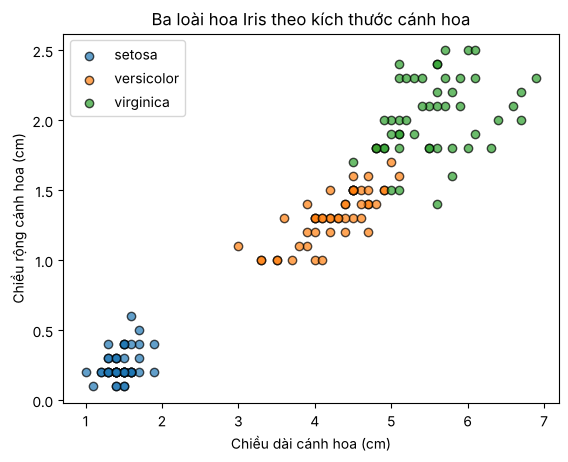

In [4]:
# ô iris_scatter
ten_loai = iris.target_names
mau = ["tab:blue", "tab:orange", "tab:green"]
for nhan in range(3):
    phan = df[df["target"] == nhan]
    plt.scatter(phan["petal length (cm)"], phan["petal width (cm)"],
                c=mau[nhan], label=ten_loai[nhan], alpha=0.7, edgecolors="k")
plt.xlabel("Chiều dài cánh hoa (cm)")
plt.ylabel("Chiều rộng cánh hoa (cm)")
plt.title("Ba loài hoa Iris theo kích thước cánh hoa")
plt.legend()
plt.show()

In [5]:
# ô tach_X_y
X = df[iris.feature_names]   # ma trận đặc trưng: 150 dòng x 4 cột
y = df["target"]             # vector nhãn: 150 giá trị 0, 1, 2
print("X có kích thước:", X.shape)
print("y có kích thước:", y.shape)

X có kích thước: (150, 4)
y có kích thước: (150,)


In [6]:
# ô iris_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("Tập huấn luyện:", X_train.shape, " Tập kiểm tra:", X_test.shape)

Tập huấn luyện: (105, 4)  Tập kiểm tra: (45, 4)


In [7]:
# ô iris_train
mo_hinh = KNeighborsClassifier(n_neighbors=5)   # "hỏi ý kiến 5 hàng xóm gần nhất"
mo_hinh.fit(X_train, y_train)                   # bước HỌC: ghi nhớ dữ liệu huấn luyện
print("Đã huấn luyện xong mô hình:", mo_hinh)

Đã huấn luyện xong mô hình: KNeighborsClassifier()


In [8]:
# ô iris_predict
y_du_doan = mo_hinh.predict(X_test)             # bước DỰ ĐOÁN trên dữ liệu chưa thấy
so_sanh = pd.DataFrame({"Thực tế": y_test.values[:8],
                        "Dự đoán": y_du_doan[:8]})
print(so_sanh)

   Thực tế  Dự đoán
0        2        2
1        1        1
2        2        2
3        1        1
4        2        2
5        2        2
6        1        1
7        1        1


In [9]:
# ô iris_accuracy
do_chinh_xac = accuracy_score(y_test, y_du_doan)
so_dung = (y_test.values == y_du_doan).sum()
print(f"Đoán đúng {so_dung}/{len(y_test)} bông hoa")
print(f"Độ chính xác (accuracy) = {do_chinh_xac:.4f}")

Đoán đúng 44/45 bông hoa
Độ chính xác (accuracy) = 0.9778


In [10]:
# ô iris_new
hoa_moi = pd.DataFrame([[5.0, 3.4, 1.5, 0.2],    # bông hoa nhỏ
                        [6.7, 3.0, 5.2, 2.3]],   # bông hoa lớn
                       columns=iris.feature_names)
du_doan = mo_hinh.predict(hoa_moi)
for i, nhan in enumerate(du_doan):
    print(f"Bông hoa {i + 1} được dự đoán là: {iris.target_names[nhan]}")

Bông hoa 1 được dự đoán là: setosa
Bông hoa 2 được dự đoán là: virginica


## Thử thay đổi số hàng xóm k

In [11]:
# ô iris_k
for k in [1, 3, 5, 15, 51]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k = {k:2d}  ->  accuracy = {m.score(X_test, y_test):.4f}")

k =  1  ->  accuracy = 0.9333
k =  3  ->  accuracy = 0.9556
k =  5  ->  accuracy = 0.9778
k = 15  ->  accuracy = 0.9556
k = 51  ->  accuracy = 0.8889


## Thực hành 1.1: Bộ dữ liệu Wine

In [12]:
# ô wine_buoc1
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)
print(wine.frame.shape)
print(wine.target_names)
print(wine.frame["target"].value_counts().sort_index())

(178, 14)
['class_0' 'class_1' 'class_2']
target
0    59
1    71
2    48
Name: count, dtype: int64


In [13]:
# ô wine_buoc2
Xw = wine.data
yw = wine.target
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    Xw, yw, test_size=0.3, random_state=42, stratify=yw)
print(Xw_train.shape, Xw_test.shape)

(124, 13) (54, 13)


In [14]:
# ô wine_buoc3
knn_wine = KNeighborsClassifier(n_neighbors=5)
knn_wine.fit(Xw_train, yw_train)
print("Accuracy trên Wine:", round(knn_wine.score(Xw_test, yw_test), 4))

Accuracy trên Wine: 0.7222


## Bài tập tự làm

Mức độ: ⭐ cơ bản, ⭐⭐ nâng cao, ⭐⭐⭐ thử thách. Viết lời giải vào ô mã trống ngay dưới mỗi bài.

**Bài 1.1.** ⭐ Liệt kê năm ứng dụng học máy mà bạn gặp hằng ngày (trên điện thoại, mạng xã hội, ngân hàng…). Với mỗi ứng dụng, cho biết đó là bài toán gì và nhãn có thể là gì.

In [ ]:
# Lời giải Bài 1.1


**Bài 1.2.** ⭐ Chạy lại toàn bộ mã của Mục 1.6 nhưng chia tập kiểm tra 20% (`test_size=0.2`). Độ chính xác thay đổi thế nào?

In [ ]:
# Lời giải Bài 1.2


**Bài 1.3.** ⭐ Đổi `random_state` thành 0, 1, 2, 3, 4 (giữ `test_size=0.3`) và ghi lại độ chính xác cho mỗi lần. Vì sao kết quả không giống nhau? Điều này nói lên gì về việc chỉ đánh giá mô hình một lần?

In [ ]:
# Lời giải Bài 1.3


**Bài 1.4.** ⭐ Dùng mô hình kNN đã huấn luyện để dự đoán loài cho ba bông hoa có số đo (theo thứ tự 4 cột): $(5,8; 2,7; 4,1; 1,0)$, $(7,2; 3,2; 6,0; 1,8)$ và $(4,6; 3,2; 1,4; 0,2)$. Đối chiếu kết quả với Hình 1.5.

In [ ]:
# Lời giải Bài 1.4


**Bài 1.5.** ⭐⭐ Vẽ biểu đồ phân tán Iris theo hai đặc trưng **của đài hoa** (`sepal length`, `sepal width`). So với Hình 1.5, ba loài có dễ phân biệt hơn không? Sau đó huấn luyện kNN chỉ với hai cột đài hoa, rồi chỉ với hai cột cánh hoa, và so sánh độ chính xác. Rút ra nhận xét về vai trò của việc chọn đặc trưng.

In [ ]:
# Lời giải Bài 1.5


**Bài 1.6.** ⭐⭐ Với bộ dữ liệu Wine ở Thực hành 1.1, thử $k = 1, 3, 5, …, 25$ (các số lẻ) và vẽ đồ thị đường biểu diễn độ chính xác theo $k$. Giá trị $k$ nào tốt nhất?

In [ ]:
# Lời giải Bài 1.6


**Bài 1.7.** ⭐⭐ Bộ dữ liệu `load_breast_cancer` trong scikit-learn chứa dữ liệu chẩn đoán u vú lành tính/ác tính. Hãy cho biết số mẫu, số đặc trưng, tên hai lớp và số mẫu mỗi lớp. Dữ liệu này có cân bằng không? Xây dựng mô hình kNN và báo cáo độ chính xác.

In [ ]:
# Lời giải Bài 1.7


**Bài 1.8.** ⭐⭐⭐ Viết hàm `du_doan_knn(X_train, y_train, x_moi, k)` **không dùng scikit-learn**: tính khoảng cách từ `x_moi` đến mọi mẫu huấn luyện, lấy $k$ mẫu gần nhất và trả về nhãn xuất hiện nhiều nhất. Gợi ý: khoảng cách giữa hai điểm $(a_1, a_2, a_3, a_4)$ và $(b_1, b_2, b_3, b_4)$ là $\sqrt{(a_1-b_1)^2 + \cdots + (a_4-b_4)^2}$ (sẽ giải thích ở Chương 3). Kiểm tra hàm của bạn cho kết quả giống `KNeighborsClassifier` trên tập kiểm tra Iris.

In [ ]:
# Lời giải Bài 1.8
